In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
data = pd.read_csv('student_performance_prediction.csv')
data.head()

,Student ID,Study Hours per Week,Attendance Rate,Previous Grades,Participation in Extracurricular Activities,Parent Education Level,Passed
0,S00001,12.5,NaN,75.0,Yes,Master,Yes
1,S00002,9.3,95.3,60.6,No,High School,No
2,S00003,13.2,NaN,64.0,No,Associate,No
3,S00004,17.6,76.8,62.4,Yes,Bachelor,No
4,S00005,8.8,89.3,72.7,No,Master,No


In [16]:
data.info()
data['Passed'].unique()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 7 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Student ID                                   40000 non-null  object 
 1   Study Hours per Week                         38005 non-null  float64
 2   Attendance Rate                              38008 non-null  float64
 3   Previous Grades                              38006 non-null  float64
 4   Participation in Extracurricular Activities  38000 non-null  object 
 5   Parent Education Level                       38000 non-null  object 
 6   Passed                                       38000 non-null  object 
dtypes: float64(3), object(4)
memory usage: 2.1+ MB


array(['Yes', 'No', nan], dtype=object)

In [17]:
for col in data.columns:
    if data[col].dtype == 'object':
        print(f"Column: {col}")
        print(data[col].value_counts())
        print("\n")

Column: Student ID
Student ID
S00001    1
S26671    1
S26664    1
S26665    1
S26666    1
         ..
S13334    1
S13335    1
S13336    1
S13337    1
S40000    1
Name: count, Length: 40000, dtype: int64


Column: Participation in Extracurricular Activities
Participation in Extracurricular Activities
No     19028
Yes    18972
Name: count, dtype: int64


Column: Parent Education Level
Parent Education Level
Bachelor       7685
High School    7675
Doctorate      7610
Associate      7604
Master         7426
Name: count, dtype: int64


Column: Passed
Passed
Yes    19011
No     18989
Name: count, dtype: int64




In [18]:
data.describe(include='all')

,Student ID,Study Hours per Week,Attendance Rate,Previous Grades,Participation in Extracurricular Activities,Parent Education Level,Passed
count,40000,38005.000000,38008.000000,38006.000000,38000,38000,38000
unique,40000,NaN,NaN,NaN,2,5,2
top,S00001,NaN,NaN,NaN,No,Bachelor,Yes
freq,1,NaN,NaN,NaN,19028,7685,19011
mean,NaN,9.962744,75.276323,65.440107,NaN,NaN,NaN
std,NaN,5.031154,20.393418,16.503119,NaN,NaN,NaN
min,NaN,-12.300000,-14.300000,8.300000,NaN,NaN,NaN
25%,NaN,6.600000,61.600000,55.100000,NaN,NaN,NaN
50%,NaN,10.000000,75.300000,65.200000,NaN,NaN,NaN
75%,NaN,13.400000,88.800000,75.200000,NaN,NaN,NaN


In [19]:
data = data.drop(columns=['Student ID'])
data.head()

,Study Hours per Week,Attendance Rate,Previous Grades,Participation in Extracurricular Activities,Parent Education Level,Passed
0,12.5,NaN,75.0,Yes,Master,Yes
1,9.3,95.3,60.6,No,High School,No
2,13.2,NaN,64.0,No,Associate,No
3,17.6,76.8,62.4,Yes,Bachelor,No
4,8.8,89.3,72.7,No,Master,No


In [20]:
mode_parent_education = data['Parent Education Level'].mode()[0]
mode_participation = data['Participation in Extracurricular Activities'].mode()[0]
# print(f"Mode of Parent Education Level: {mode_parent_education}")
# print(f"Mode of Participation in Extracurricular Activities: {mode_participation}")
data['Parent Education Level'] = data['Parent Education Level'].fillna(mode_parent_education)
data['Participation in Extracurricular Activities'] = data['Participation in Extracurricular Activities'].fillna(mode_participation)
# data['Parent Education Level'].isnull().sum()

In [21]:
# TODO: try to use regression to fix invalid values in Previous Grades, Attendance Rate, and Study Hours
# for now convert all invalid values to nan
data.loc[
    (data['Previous Grades'] < 0) | (data['Previous Grades'] > 100) |
    (data['Attendance Rate'] < 0) | (data['Attendance Rate'] > 100) |
    (data['Study Hours per Week'] < 0),
    ['Previous Grades', 'Attendance Rate', 'Study Hours per Week']
] = np.nan
print(data['Previous Grades'].isnull().sum(), data['Attendance Rate'].isnull().sum(), data['Study Hours per Week'].isnull().sum())

7148 7326 7173


In [ ]:
# fix 1: regression to fix invalid values in Previous Grades, Attendance Rate, and Study Hours columns by columns
# use KNNImputer to fill in missing values
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split

data = data[data['Passed'].notnull()]
features = ['Previous Grades', 'Attendance Rate', 'Study Hours per Week']
X = data[features]
y = data['Passed'].map({'Yes': 1, 'No': 0})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

KNN_imputer = KNNImputer(n_neighbors=5, weights='distance')
X_train = KNN_imputer.fit_transform(X_train)
X_test = KNN_imputer.transform(X_test)

data[features] = np.vstack((X_train, X_test))

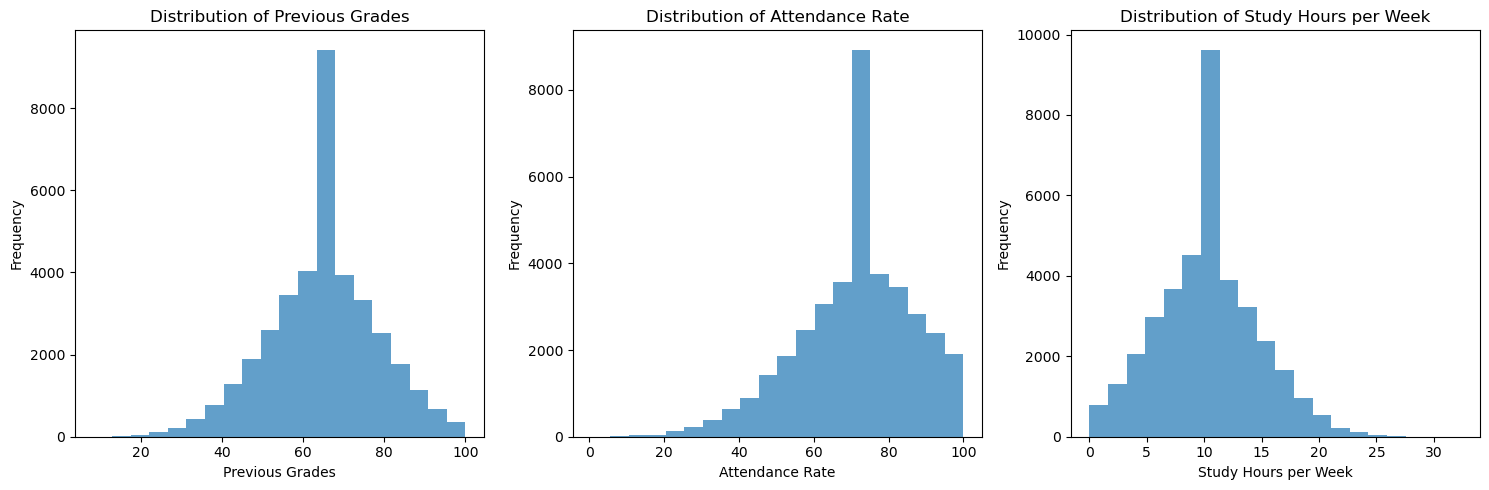

In [23]:
# plot the newly filled values for Previous Grades, Attendance Rate, and Study Hours per Week
plt.figure(figsize=(15, 5))

for i, feature in enumerate(features):
    plt.subplot(1, 3, i + 1)
    plt.hist(data[feature], bins=20, alpha=0.7)
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.title(f'Distribution of {feature}')

plt.tight_layout()
plt.show()

In [10]:
# fix 2: try to fill in missing values with median values for Previous Grades, Attendance Rate, and Study Hours per Week
median_previous_grades = data['Previous Grades'].median()
median_attendance_rate = data['Attendance Rate'].median()
median_study_hours = data['Study Hours per Week'].median()

data['Previous Grades'] = data['Previous Grades'].fillna(median_previous_grades)
data['Attendance Rate'] = data['Attendance Rate'].fillna(median_attendance_rate)
data['Study Hours per Week'] = data['Study Hours per Week'].fillna(median_study_hours)

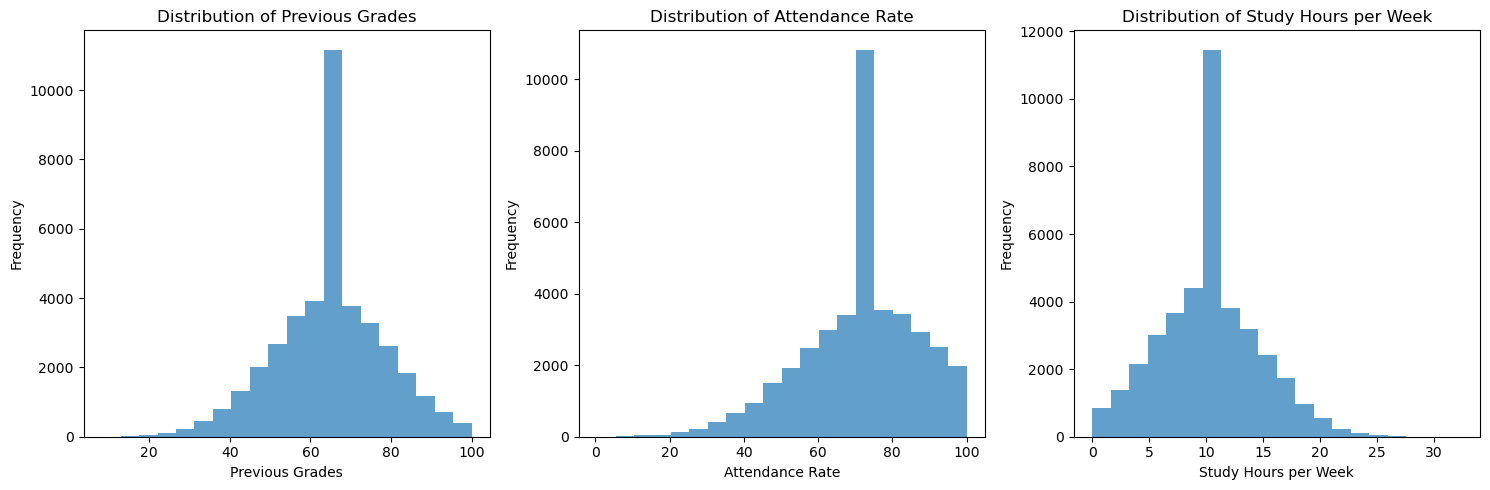

In [12]:
# plot the newly filled values for Previous Grades, Attendance Rate, and Study Hours per Week
features = ['Previous Grades', 'Attendance Rate', 'Study Hours per Week']
plt.figure(figsize=(15, 5))

for i, feature in enumerate(features):
    plt.subplot(1, 3, i + 1)
    plt.hist(data[feature], bins=20, alpha=0.7)
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.title(f'Distribution of {feature}')

plt.tight_layout()
plt.show()

In [24]:
# update the csv file with the cleaned data
data.to_csv('student_performance_prediction_cleaned.csv', index=False)